# 🐶🐱 Cats vs Dogs Image Classification End-to-End Project

---

## 1. Executive Summary

This project demonstrates building an end-to-end **Convolutional Neural Network (CNN)** for binary image classification (**Cats vs. Dogs**) using TensorFlow and Keras in Google Colab.

### Key Highlights
* **Dataset:** Kaggle Dogs vs. Cats dataset (processed using Kaggle API).
* **Data Pipeline:** Keras `image_dataset_from_directory` generators for memory-efficient mini-batch loading and normalization. ( Used Documentation for Code)
* **Architecture:** Sequential CNN with alternating Conv2D, BatchNorm, MaxPooling2D, and Dropout layers.
* **Overfitting Resolution:** Applied **Batch Normalization** and **Dropout** to close the gap between training and validation accuracy.
* **Inference Pipeline:** Preprocessing and prediction on unseen web images using OpenCV (`cv2`).

In [1]:
from pathlib import Path 

import tensorflow as tf 
from tensorflow import keras 
from tensorflow.keras import Sequential 
from tensorflow.keras.layers import Dense, Conv2D, MaxPooling2D , Flatten , BatchNormalization, Dropout, Input  

import matplotlib.pyplot as plt 
import cv2 

I0000 00:00:1793958177.759410     564 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793958178.125194     564 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793958179.856652     564 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [2]:
# Point directly to the train and test folders in the current working directory
train_dir = Path("train")
test_dir = Path("test")

In [3]:
# Lets training dataset
train_ds = keras.utils.image_dataset_from_directory(
    directory=train_dir,
    labels='inferred',
    label_mode='int',     # 0 for Cat , 1 for Dog
    batch_size = 32,
    image_size = (256,256)
)

# Load test dataset
test_ds = keras.utils.image_dataset_from_directory(
    directory=test_dir,
    labels='inferred',
    label_mode='int',    
    batch_size = 32,
    image_size = (256,256)
)

Found 20000 files belonging to 2 classes.


I0000 00:00:1793958193.717185     564 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 3536 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4050 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.9


Found 5000 files belonging to 2 classes.


In [4]:
# Normalize Pixel values from [0,255] to [0,1]
def process(image,label): 
    image = tf.cast(image / 255, tf.float32) 
    return image, label 

train_ds = train_ds.map(process) 
validation_ds = test_ds.map(process) 


### Baseline vs. Regularized Architecture

* **Baseline CNN:** Exhibited severe overfitting—training accuracy reached ~95% while validation accuracy plateaued around ~75–80%.
* **Regularized CNN (Final):** Added **Batch Normalization** (after Convolutional layers) and **Dropout** (in Dense and Convolutional layers) to stabilize gradients, reduce internal covariate shift, and prevent overfitting.

In [5]:
# Building CNN Model 
model = Sequential([
    # 1st Convolutional Block
    Input(shape=(256,256,3)),
    Conv2D(32,kernel_size=(3,3),padding='valid',activation='relu'),
    BatchNormalization(),
    MaxPooling2D(pool_size=(2,2),strides=2,padding='valid'),

    # 2nd Convolutional Block
    Conv2D(64,kernel_size=(3,3),padding='valid',activation='relu'),
    BatchNormalization(),
    MaxPooling2D(pool_size=(2,2),strides=2,padding='valid'),

    # 3rd Convolutional Block
    Conv2D(128,kernel_size=(3,3),padding='valid',activation='relu'),
    BatchNormalization(),
    MaxPooling2D(pool_size=(2,2),strides=2,padding='valid'),

    # Flattening and Fully Connected Layers
    Flatten(),

    Dense(128,activation='relu'),
    Dropout(0.1),

    Dense(64,activation='relu'),
    Dropout(0.1),

    # Output Layer for Binary Classification
    Dense(1,activation='sigmoid')
])

In [6]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 254, 254, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 254, 254, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 127, 127, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 125, 125, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 125, 125, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 62, 62, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 60, 60, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 60, 60, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 30, 30, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 115200)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    14,745,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,848,193 (56.64 MB)

 Trainable params: 14,847,745 (56.64 MB)

 Non-trainable params: 448 (1.75 KB)

In [7]:
# MODEL COMPILATION
model.compile(optimizer='adam',
              loss='binary_crossentropy',
              metrics=['accuracy'])

In [8]:
# Execute training across 10 epochs
history = model.fit(train_ds, epochs=10, validation_data=validation_ds) 

Epoch 1/10


/home/shubham/dl-gpu/.venv/lib/python3.13/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
I0000 00:00:1793958205.218184     693 service.cc:153] XLA service 0x78dbd803aa60 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1793958205.218229     693 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 4050 Laptop GPU, Compute Capability 8.9 (Driver: 13.5.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.28.0)
I0000 00:00:1793958205.318096     693 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1793958205.903735     693 cuda_dnn.cc:461] Loaded cuDNN version 92800
I0000 00:00:1793958206.005819     693 dot_merger.cc:481]

625/625 ━━━━━━━━━━━━━━━━━━━━ 78s 102ms/step - accuracy: 0.5904 - loss: 1.3503 - val_accuracy: 0.6558 - val_loss: 0.6542
Epoch 2/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 61s 97ms/step - accuracy: 0.7019 - loss: 0.5800 - val_accuracy: 0.6684 - val_loss: 0.6460
Epoch 3/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 61s 98ms/step - accuracy: 0.7623 - loss: 0.4913 - val_accuracy: 0.7206 - val_loss: 0.5864
Epoch 4/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 60s 96ms/step - accuracy: 0.7917 - loss: 0.4553 - val_accuracy: 0.7748 - val_loss: 0.4709
Epoch 5/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 61s 97ms/step - accuracy: 0.8332 - loss: 0.3756 - val_accuracy: 0.7546 - val_loss: 0.5467
Epoch 6/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 60s 97ms/step - accuracy: 0.8676 - loss: 0.3109 - val_accuracy: 0.6612 - val_loss: 0.7364
Epoch 7/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 60s 96ms/step - accuracy: 0.8993 - loss: 0.2443 - val_accuracy: 0.6504 - val_loss: 1.1929
Epoch 8/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 60s 97ms/step - accuracy: 0.9238 - loss: 0.1936 - val_accura

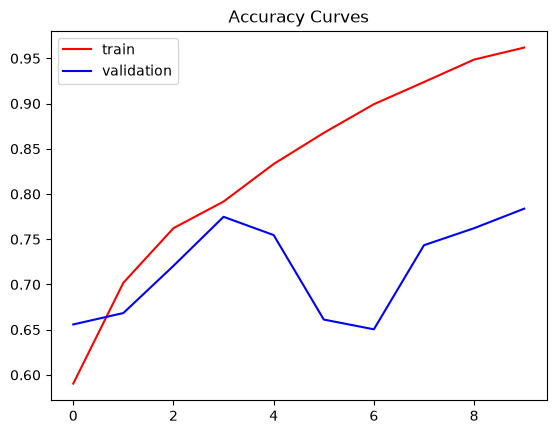

In [9]:
# Accuracy Plot
plt.plot(history.history['accuracy'], color='red', label='train')
plt.plot(history.history['val_accuracy'], color='blue', label='validation')
plt.title('Accuracy Curves')
plt.legend()
plt.show()

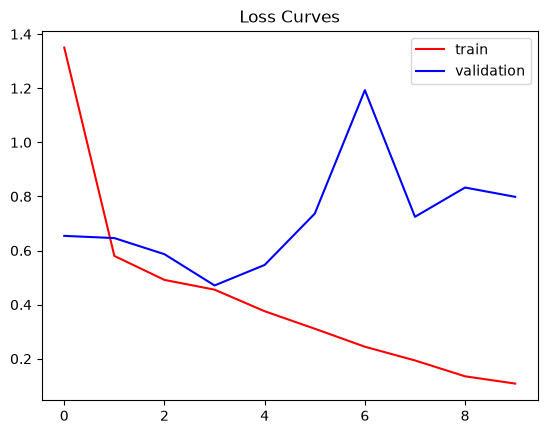

In [10]:
# Loss Plot
plt.plot(history.history['loss'], color='red', label='train')
plt.plot(history.history['val_loss'], color='blue', label='validation')
plt.title('Loss Curves')
plt.legend()
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
Prediction: CAT 


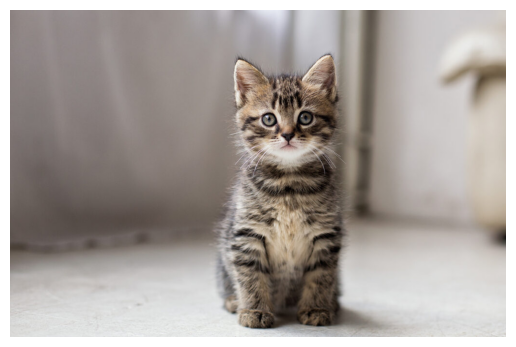

In [16]:
# Lets Test our model on UNSEEN data 

# Load unseen image (OpenCV loads as BGR)
test_img = cv2.imread('unseen-cat.jpg')

# Convert BGR -> RGB so it matches the training data
test_img = cv2.cvtColor(test_img, cv2.COLOR_BGR2RGB)

# Preprocess
test_img_resized = cv2.resize(test_img, (256, 256))
test_input = test_img_resized.reshape((1, 256, 256, 3)) / 255.0

# Predict (0 = Cat, 1 = Dog)
prediction = model.predict(test_input)
if prediction[0][0] > 0.5:
    print("Prediction: DOG ")
else:
    print("Prediction: CAT ")

# Display (no extra conversion needed now)
plt.imshow(test_img)
plt.axis('off')
plt.show()


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step
Prediction: DOG 


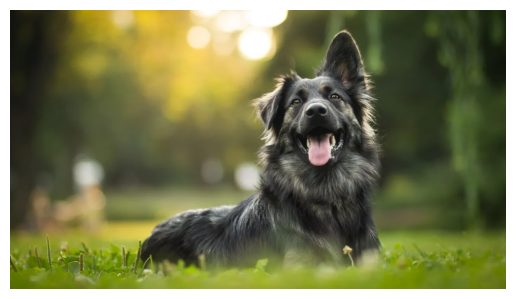

In [18]:
# Load unseen image (OpenCV loads as BGR)
test_img = cv2.imread('unseen-Dog.jpg')

# Convert BGR -> RGB so it matches the training data
test_img = cv2.cvtColor(test_img, cv2.COLOR_BGR2RGB)                     # Imp 

# Preprocess
test_img_resized = cv2.resize(test_img, (256, 256))
test_input = test_img_resized.reshape((1, 256, 256, 3)) / 255.0

# Predict (0 = Cat, 1 = Dog)
prediction = model.predict(test_input)
if prediction[0][0] > 0.5:
    print("Prediction: DOG ")
else:
    print("Prediction: CAT ")

# Display (no extra conversion needed now)
plt.imshow(test_img)
plt.axis('off')
plt.show()